Import libraries

In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

Enter API key and city

In [ ]:
API_KEY = "ee36769fa1ade618962ede20aa6168f8"

city = "Pune"
country = "IN"

url = f"https://api.openweathermap.org/data/2.5/forecast?q={city},{country}&appid={API_KEY}&units=metric"

response = requests.get(url)

print(response.status_code)

200


Check and read API response

In [ ]:
data = response.json()

print(data.keys())
print(data['city'])

dict_keys(['cod', 'message', 'cnt', 'list', 'city'])
{'id': 1259229, 'name': 'Pune', 'coord': {'lat': 18.5196, 'lon': 73.8553}, 'country': 'IN', 'population': 9999, 'timezone': 19800, 'sunrise': 1790729684, 'sunset': 1790772872}


Extract weather data

In [ ]:
weather = []

for item in data['list']:
    weather.append({
        'Date': item['dt_txt'],
        'Temperature': item['main']['temp'],
        'Humidity': item['main']['humidity'],
        'Wind_Speed': item['wind']['speed'],
        'Rain_Probability': item.get('pop', 0)
    })

df = pd.DataFrame(weather)

print(df.head())

                  Date  Temperature  Humidity  Wind_Speed  Rain_Probability
0  2026-09-30 18:00:00        25.91        60        1.17              0.82
1  2026-09-30 21:00:00        24.30        71        1.17              0.00
2  2026-10-01 00:00:00        25.11        77        0.60              0.00
3  2026-10-01 03:00:00        27.15        70        0.85              0.00
4  2026-10-01 06:00:00        30.29        50        3.02              0.00


Clean and preprocess

In [ ]:
df['Date'] = pd.to_datetime(df['Date'])
df = df.drop_duplicates()
df = df.fillna(0)

print(df.isnull().sum())
print(df.head())

Date                0
Temperature         0
Humidity            0
Wind_Speed          0
Rain_Probability    0
dtype: int64
                 Date  Temperature  Humidity  Wind_Speed  Rain_Probability
0 2026-09-30 18:00:00        25.91        60        1.17              0.82
1 2026-09-30 21:00:00        24.30        71        1.17              0.00
2 2026-10-01 00:00:00        25.11        77        0.60              0.00
3 2026-10-01 03:00:00        27.15        70        0.85              0.00
4 2026-10-01 06:00:00        30.29        50        3.02              0.00


Explore the dataset

In [ ]:
print(df.shape)
print(df.info())
print(df.describe())

(40, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Date              40 non-null     datetime64[ns]
 1   Temperature       40 non-null     float64       
 2   Humidity          40 non-null     int64         
 3   Wind_Speed        40 non-null     float64       
 4   Rain_Probability  40 non-null     float64       
dtypes: datetime64[ns](1), float64(3), int64(1)
memory usage: 1.7 KB
None
                      Date  Temperature   Humidity  Wind_Speed  \
count                   40    40.000000  40.000000   40.000000   
mean   2026-10-03 04:30:00    27.530500  60.000000    1.889000   
min    2026-09-30 18:00:00    22.830000  34.000000    0.430000   
25%    2026-10-01 23:15:00    24.972500  47.750000    1.097500   
50%    2026-10-03 04:30:00    26.720000  62.500000    1.700000   
75%    2026-10-04 09:45:00    30.237500  7

Average, minimum and maximum

In [ ]:
print("Average Temperature:", df['Temperature'].mean())
print("Minimum Temperature:", df['Temperature'].min())
print("Maximum Temperature:", df['Temperature'].max())

Average Temperature: 27.5305
Minimum Temperature: 22.83
Maximum Temperature: 34.29


Temperature Trend

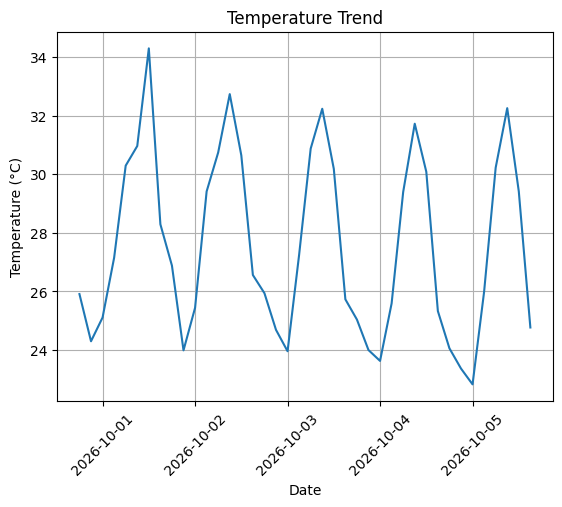

In [ ]:
plt.plot(df['Date'], df['Temperature'])

plt.title('Temperature Trend')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.xticks(rotation=45)
plt.grid()
plt.show()

Humidity and Wind Speed

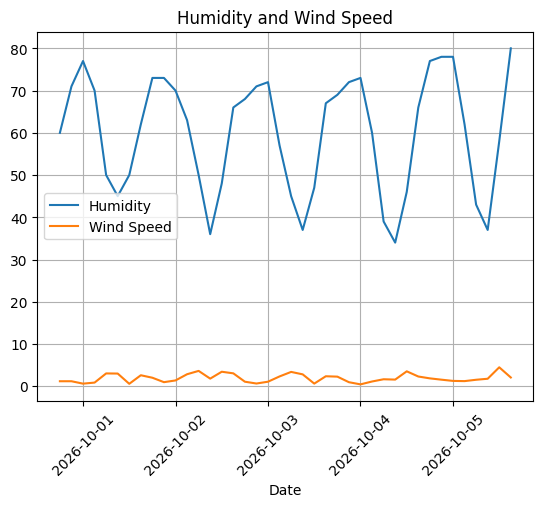

In [ ]:
plt.plot(df['Date'], df['Humidity'], label='Humidity')
plt.plot(df['Date'], df['Wind_Speed'], label='Wind Speed')

plt.title('Humidity and Wind Speed')
plt.xlabel('Date')
plt.legend()
plt.xticks(rotation=45)
plt.grid()
plt.show()

Precipitation Probability

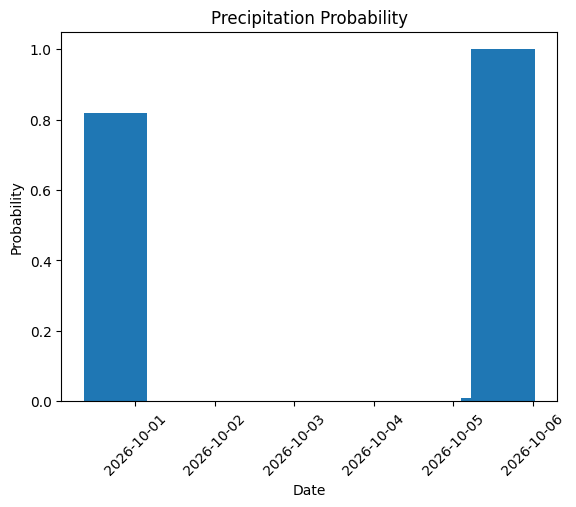

In [ ]:
plt.bar(df['Date'], df['Rain_Probability'])

plt.title('Precipitation Probability')
plt.xlabel('Date')
plt.ylabel('Probability')
plt.xticks(rotation=45)
plt.show()

Daily Average Weather

In [ ]:
daily = df.groupby(df['Date'].dt.date)[
    ['Temperature', 'Humidity', 'Wind_Speed']
].mean()

print(daily)

            Temperature   Humidity  Wind_Speed
Date                                          
2026-09-30    25.105000  65.500000    1.170000
2026-10-01    28.370000  62.500000    1.695000
2026-10-02    28.268750  59.000000    2.218750
2026-10-03    27.407500  58.250000    1.963750
2026-10-04    26.646250  59.125000    1.742500
2026-10-05    27.578333  59.666667    2.043333


Correlation

In [ ]:
correlation = df[
    ['Temperature', 'Humidity', 'Wind_Speed', 'Rain_Probability']
].corr()

print(correlation)

                  Temperature  Humidity  Wind_Speed  Rain_Probability
Temperature          1.000000 -0.905226    0.423829         -0.164601
Humidity            -0.905226  1.000000   -0.355804          0.183549
Wind_Speed           0.423829 -0.355804    1.000000         -0.049324
Rain_Probability    -0.164601  0.183549   -0.049324          1.000000


Correlation Heatmap

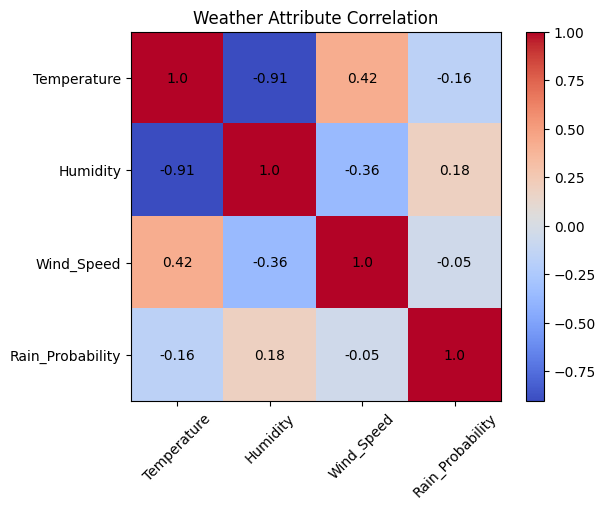

In [ ]:
plt.imshow(correlation, cmap='coolwarm')
plt.colorbar()

plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45)
plt.yticks(range(len(correlation.columns)), correlation.columns)

for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(j, i, round(correlation.iloc[i, j], 2),
                 ha='center', va='center')

plt.title('Weather Attribute Correlation')
plt.show()


Geographical Information

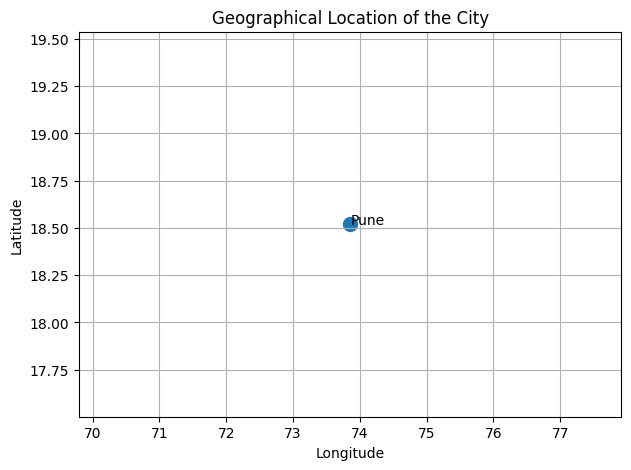

In [ ]:
plt.figure(figsize=(7,5))

plt.scatter(longitude, latitude, s=100)

plt.text(longitude, latitude, data['city']['name'])

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Location of the City")

plt.grid(True)
plt.show()